# 05 — Aprendizaje por refuerzo: Monte Carlo

**Escenario 4:** Efectividad de campañas de marketing
**Dataset:** `data/raw/bank-additional-full.csv` (se usa para estimar las probabilidades del entorno)

**Objetivo:** simular campañas comerciales en las que un agente decide cómo contactar a cada cliente (qué canal usar, si ofrecer una promoción o si dejar de llamar) y aprender con el método Monte Carlo qué estrategia da más ganancia acumulada según las conversiones simuladas.

Como pide la consigna, no se aplica el algoritmo directamente sobre el CSV. Se construye un **entorno simulado** donde el agente observa estados, toma acciones y recibe recompensas. El dataset se usa solo para que las probabilidades de conversión del entorno sean realistas.

## 1. Fundamento teórico

### Aprendizaje por refuerzo

En el aprendizaje por refuerzo un **agente** interactúa con un **entorno**. En cada paso $t$:

1. observa un **estado** $s_t$,
2. elige una **acción** $a_t$,
3. recibe una **recompensa** $r_{t+1}$ y pasa a un nuevo estado $s_{t+1}$.

El objetivo del agente es aprender una **política** $\pi(s)$ (qué acción tomar en cada estado) que maximice la recompensa acumulada.

### Retorno

La recompensa acumulada desde el paso $t$ hasta el final del episodio se llama **retorno**:

$$G_t = r_{t+1} + \gamma\, r_{t+2} + \gamma^2 r_{t+3} + \dots = \sum_{k=0}^{T-t-1} \gamma^{k}\, r_{t+k+1}$$

donde $\gamma \in [0, 1]$ es el **factor de descuento**: mientras más pequeño, más importan las recompensas inmediatas frente a las futuras.

### Función de valor acción-estado

$Q(s, a)$ es el retorno esperado si en el estado $s$ se toma la acción $a$ y después se sigue la política $\pi$:

$$Q^{\pi}(s, a) = \mathbb{E}_{\pi}\left[ G_t \mid s_t = s,\; a_t = a \right]$$

### Método Monte Carlo

Monte Carlo estima $Q(s,a)$ **promediando los retornos reales** obtenidos al jugar episodios completos. No necesita conocer las probabilidades del entorno (es *model-free*), solo necesita experiencia.

Se usa la variante **first-visit** (primera visita): en cada episodio, para cada par $(s,a)$ solo se toma en cuenta la primera vez que aparece. La actualización como promedio incremental es:

$$N(s,a) \leftarrow N(s,a) + 1$$
$$Q(s,a) \leftarrow Q(s,a) + \frac{1}{N(s,a)} \left[ G_t - Q(s,a) \right]$$

Una diferencia importante con Q-Learning o SARSA es que Monte Carlo **espera a que termine el episodio** para actualizar, porque necesita el retorno completo $G_t$.

### Política ε-greedy

Para que el agente no se quede siempre con la primera acción que le funcionó, se usa una política ε-greedy:

$$\pi(s) = \begin{cases} \text{acción aleatoria} & \text{con probabilidad } \varepsilon \\ \arg\max_a Q(s,a) & \text{con probabilidad } 1-\varepsilon \end{cases}$$

Al inicio $\varepsilon$ es alto (explora mucho) y va bajando con los episodios (explota lo aprendido):

$$\varepsilon_{e} = \max\left(\varepsilon_{min},\; \varepsilon_{0} \cdot \text{decay}^{\,e}\right)$$

Esta combinación de evaluar $Q$ con Monte Carlo y mejorar la política con ε-greedy se conoce como **control Monte Carlo on-policy**.

## 2. Librerías y carga de datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
from collections import defaultdict

sns.set_theme(style="whitegrid", palette="deep")
SEED = 42

df = pd.read_csv("../data/raw/bank-additional-full.csv", sep=";").drop_duplicates()
df["y_bin"] = (df["y"] == "yes").astype(int)
print("Registros:", len(df))

Registros: 41176


## 3. Estimación de probabilidades desde el dataset

Para que la simulación sea realista, las probabilidades de que un cliente acepte se calculan con los datos reales.

### 3.1 Perfiles de cliente

Según el EDA, lo que más cambia la probabilidad de aceptar es el historial de campañas y el tipo de trabajo. Con eso se definen 4 perfiles:

| Perfil | Regla |
|---|---|
| `exito_previo` | Aceptó en una campaña anterior (`poutcome = success`) |
| `fallo_previo` | Fue contactado antes y no aceptó (`poutcome = failure`) |
| `receptivo` | Nunca contactado y es estudiante o jubilado |
| `nuevo` | Nunca contactado y cualquier otro trabajo |

In [2]:
def asignar_perfil(fila):
    if fila["poutcome"] == "success":
        return "exito_previo"
    if fila["poutcome"] == "failure":
        return "fallo_previo"
    if fila["job"] in ("student", "retired"):
        return "receptivo"
    return "nuevo"

df["perfil"] = df.apply(asignar_perfil, axis=1)
PERFILES = ["nuevo", "fallo_previo", "receptivo", "exito_previo"]

freq_perfil = df["perfil"].value_counts(normalize=True).reindex(PERFILES)
print("Frecuencia de cada perfil (se usa para generar clientes en la simulación):")
print((freq_perfil * 100).round(2))

Frecuencia de cada perfil (se usa para generar clientes en la simulación):
perfil
nuevo           81.67
fallo_previo    10.33
receptivo        4.67
exito_previo     3.33
Name: proportion, dtype: float64


### 3.2 Probabilidad de conversión por perfil y canal

In [3]:
prob_canal = df.groupby(["perfil", "contact"])["y_bin"].mean().unstack().reindex(PERFILES)
conteo = df.groupby(["perfil", "contact"]).size().unstack().reindex(PERFILES)
print("Tasa de conversión (%) por perfil y canal:")
print((prob_canal * 100).round(1))
print("\nCantidad de clientes en cada grupo:")
print(conteo)

Tasa de conversión (%) por perfil y canal:
contact       cellular  telephone
perfil                           
nuevo             10.7        4.5
fallo_previo      14.4       11.3
receptivo         27.0        8.7
exito_previo      65.2       64.1

Cantidad de clientes en cada grupo:
contact       cellular  telephone
perfil                           
nuevo            19630      13997
fallo_previo      3952        300
receptivo         1283        641
exito_previo      1270        103


### 3.3 Efecto de insistir (número de llamadas)

En el EDA se vio que mientras más veces se llama a un cliente, menos acepta. Se calcula un **factor de desgaste**: la tasa de conversión con $k$ llamadas dividida entre la tasa con 1 llamada.

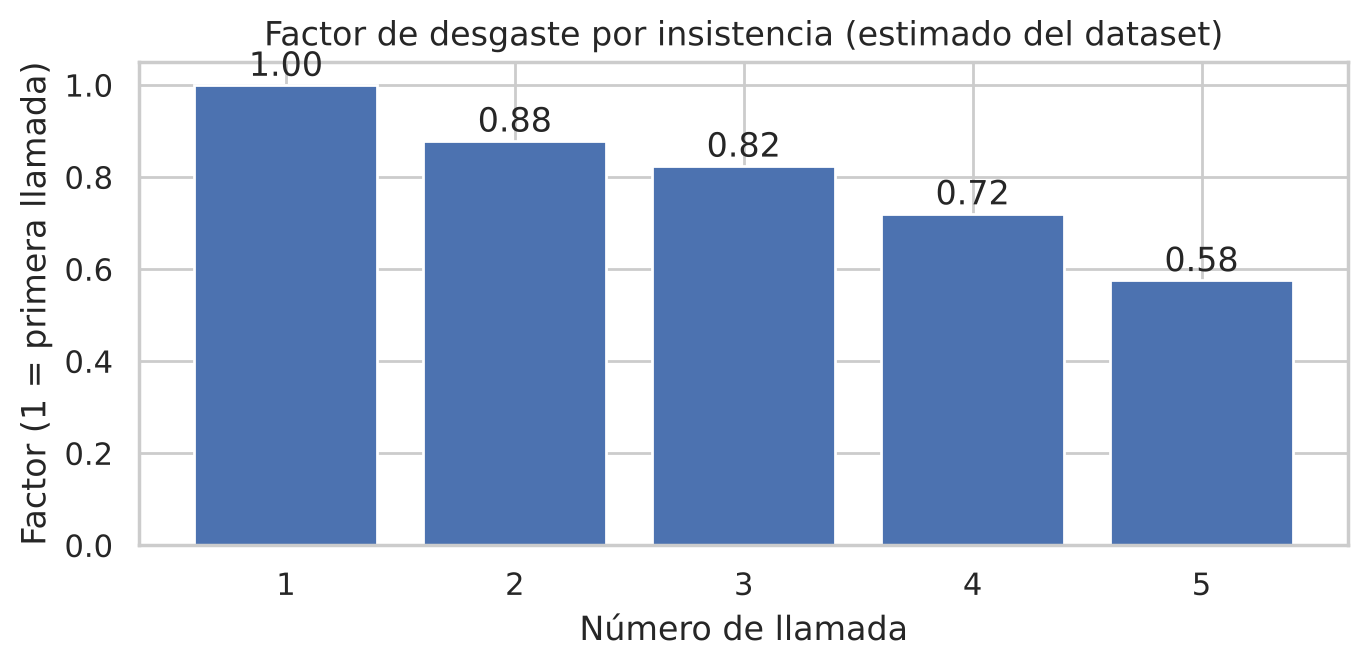

In [4]:
tasa_campaign = df.groupby("campaign")["y_bin"].mean()
MAX_CONTACTOS = 5
desgaste = (tasa_campaign.loc[1:MAX_CONTACTOS] / tasa_campaign.loc[1]).values

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(range(1, MAX_CONTACTOS + 1), desgaste, color="#4C72B0")
for i, v in enumerate(desgaste):
    ax.text(i + 1, v + 0.02, f"{v:.2f}", ha="center")
ax.set_xlabel("Número de llamada")
ax.set_ylabel("Factor (1 = primera llamada)")
ax.set_title("Factor de desgaste por insistencia (estimado del dataset)")
plt.tight_layout()
plt.show()

## 4. Definición del entorno

### Estados

El estado es una tupla **(perfil del cliente, número de llamadas ya realizadas)**:

- perfil: `nuevo`, `fallo_previo`, `receptivo`, `exito_previo` (4 valores)
- llamadas realizadas: 0, 1, 2, 3, 4 (5 valores)

En total hay **4 × 5 = 20 estados**.

### Acciones

| Acción | Descripción | Costo por llamada |
|---|---|---|
| 0 — `fijo` | Llamar al teléfono fijo | 2 |
| 1 — `celular` | Llamar al celular | 4 |
| 2 — `celular_promo` | Llamar al celular y ofrecer una tasa promocional | 4 |
| 3 — `detener` | No volver a contactar al cliente | 0 |

### Función de recompensa

| Evento | Recompensa |
|---|---|
| El cliente acepta el depósito (sin promoción) | +50 − costo de la llamada |
| El cliente acepta con promoción | +40 − costo de la llamada (la promoción le cuesta 10 al banco) |
| El cliente no acepta | − costo de la llamada |
| El cliente se molesta y rechaza definitivamente | − costo de la llamada − 5 (daño a la relación con el cliente) |
| Detener | 0 |

### Probabilidad de que el cliente acepte

$$P(\text{acepta}) = P(\text{perfil}, \text{canal}) \times \text{desgaste}(k) \; [+\,0.05 \text{ si hay promoción}]$$

donde $P(\text{perfil}, \text{canal})$ y $\text{desgaste}(k)$ salen del dataset (secciones 3.2 y 3.3).

### Condición de terminación

El episodio (un cliente) termina cuando pasa una de estas cosas:

1. El cliente **acepta** el depósito.
2. El cliente **se molesta y rechaza definitivamente**. Después de cada llamada fallida esto pasa con probabilidad $0.10 + 0.05k$, que crece con cada llamada.
3. El agente elige **detener**.
4. Se llega al **máximo de 5 llamadas**.

### Supuestos de la simulación

Algunos valores no están en el dataset y se definieron como supuestos razonables:

- La ganancia por depósito (50), los costos de llamada (2 y 4), el costo de la promoción (10) y la penalización por molestar al cliente (5) son valores simulados.
- El efecto de la promoción (+5 puntos porcentuales) es un supuesto, porque el dataset no tiene información de promociones.
- Las tasas de conversión del dataset son por cliente, no por llamada, así que se usan como una aproximación de la probabilidad de cada llamada.

In [5]:
ACCIONES = ["fijo", "celular", "celular_promo", "detener"]
COSTO = {0: 2, 1: 4, 2: 4, 3: 0}
GANANCIA = 50
COSTO_PROMO = 10
EFECTO_PROMO = 0.05
PENALIZACION_RECHAZO = 5


class CampanaEnv:
    """Entorno simulado de una campaña de telemarketing para un cliente."""

    def __init__(self, prob_canal, desgaste, freq_perfil, seed=None):
        self.prob_canal = prob_canal
        self.desgaste = desgaste
        self.freq_perfil = freq_perfil
        self.rng = np.random.default_rng(seed)

    def reset(self, perfil=None):
        if perfil is None:
            perfil = self.rng.choice(PERFILES, p=self.freq_perfil.values)
        self.perfil = perfil
        self.contactos = 0
        return (self.perfil, self.contactos)

    def step(self, accion):
        if accion == 3:  # detener
            return None, 0.0, True, {"resultado": "detenido"}

        canal = "telephone" if accion == 0 else "cellular"
        p = self.prob_canal.loc[self.perfil, canal] * self.desgaste[self.contactos]
        if accion == 2:
            p += EFECTO_PROMO
        self.contactos += 1

        if self.rng.random() < p:  # el cliente acepta
            ganancia = GANANCIA - (COSTO_PROMO if accion == 2 else 0)
            return None, ganancia - COSTO[accion], True, {"resultado": "acepta"}

        p_rechazo = 0.10 + 0.05 * (self.contactos - 1)
        if self.rng.random() < p_rechazo:  # el cliente se molesta
            return None, -COSTO[accion] - PENALIZACION_RECHAZO, True, {"resultado": "rechazo"}

        if self.contactos >= MAX_CONTACTOS:
            return None, -COSTO[accion], True, {"resultado": "max_llamadas"}

        return (self.perfil, self.contactos), -COSTO[accion], False, {"resultado": "sigue"}


env = CampanaEnv(prob_canal, desgaste, freq_perfil, seed=SEED)

### Prueba del entorno

Antes de entrenar se juega un episodio con acciones al azar para comprobar que el entorno responde bien.

In [6]:
rng_demo = np.random.default_rng(1)
estado = env.reset(perfil="nuevo")
print("Estado inicial:", estado)
terminado, total = False, 0
while not terminado:
    accion = int(rng_demo.integers(0, 3))
    nuevo_estado, r, terminado, info = env.step(accion)
    total += r
    print(f"  acción={ACCIONES[accion]:<14} recompensa={r:>6.1f}  resultado={info['resultado']:<12} siguiente estado={nuevo_estado}")
print("Recompensa total del episodio:", total)

Estado inicial: ('nuevo', 0)
  acción=celular        recompensa=  -4.0  resultado=sigue        siguiente estado=('nuevo', 1)
  acción=celular        recompensa=  -4.0  resultado=sigue        siguiente estado=('nuevo', 2)
  acción=celular_promo  recompensa=  36.0  resultado=acepta       siguiente estado=None
Recompensa total del episodio: 28


## 5. Algoritmo Monte Carlo (first-visit, on-policy, ε-greedy)

In [7]:
def elegir_accion(Q, estado, epsilon, rng):
    if rng.random() < epsilon:
        return int(rng.integers(len(ACCIONES)))
    return int(np.argmax(Q[estado]))


def generar_episodio(env, Q, epsilon, rng):
    episodio = []
    estado = env.reset()
    terminado = False
    while not terminado:
        accion = elegir_accion(Q, estado, epsilon, rng)
        siguiente, r, terminado, info = env.step(accion)
        episodio.append((estado, accion, r))
        estado = siguiente
    return episodio, info["resultado"]


def entrenar_mc(env, n_episodios=100000, gamma=0.9, eps_inicial=1.0, eps_min=0.05, eps_decay=0.99995, seed=SEED):
    rng = np.random.default_rng(seed)
    Q = defaultdict(lambda: np.zeros(len(ACCIONES)))
    N = defaultdict(lambda: np.zeros(len(ACCIONES)))
    historial = {"recompensa": [], "epsilon": [], "largo": [], "acepta": []}
    epsilon = eps_inicial

    for e in range(n_episodios):
        episodio, resultado = generar_episodio(env, Q, epsilon, rng)

        # Calcular retornos desde el final hacia el inicio
        G = 0.0
        retornos = []
        for estado, accion, r in reversed(episodio):
            G = gamma * G + r
            retornos.append((estado, accion, G))
        retornos.reverse()

        # First-visit: actualizar solo la primera aparición de cada (s, a)
        visitados = set()
        for estado, accion, G in retornos:
            if (estado, accion) in visitados:
                continue
            visitados.add((estado, accion))
            N[estado][accion] += 1
            Q[estado][accion] += (G - Q[estado][accion]) / N[estado][accion]

        historial["recompensa"].append(sum(r for _, _, r in episodio))
        historial["epsilon"].append(epsilon)
        historial["largo"].append(len(episodio))
        historial["acepta"].append(1 if resultado == "acepta" else 0)
        epsilon = max(eps_min, epsilon * eps_decay)

    return Q, N, pd.DataFrame(historial)

## 6. Entrenamiento

| Parámetro | Valor | Significado |
|---|---|---|
| Episodios | 100.000 | Cantidad de clientes simulados |
| γ (gamma) | 0,9 | Factor de descuento |
| ε inicial | 1,0 | Al inicio todas las acciones son aleatorias |
| ε mínimo | 0,05 | Siempre se mantiene un 5% de exploración |
| Decaimiento de ε | 0,99995 | ε baja poco a poco y llega a 0,05 cerca del episodio 60.000 |

In [8]:
PARAMS = dict(n_episodios=100000, gamma=0.9, eps_inicial=1.0, eps_min=0.05, eps_decay=0.99995)
Q, N, hist = entrenar_mc(CampanaEnv(prob_canal, desgaste, freq_perfil, seed=SEED), **PARAMS)
print(f"Episodios entrenados: {len(hist):,}")
print(f"Estados visitados: {len(Q)}")
print(f"ε final: {hist['epsilon'].iloc[-1]:.3f}")

Episodios entrenados: 100,000
Estados visitados: 20
ε final: 0.050


## 7. Evolución de la recompensa acumulada

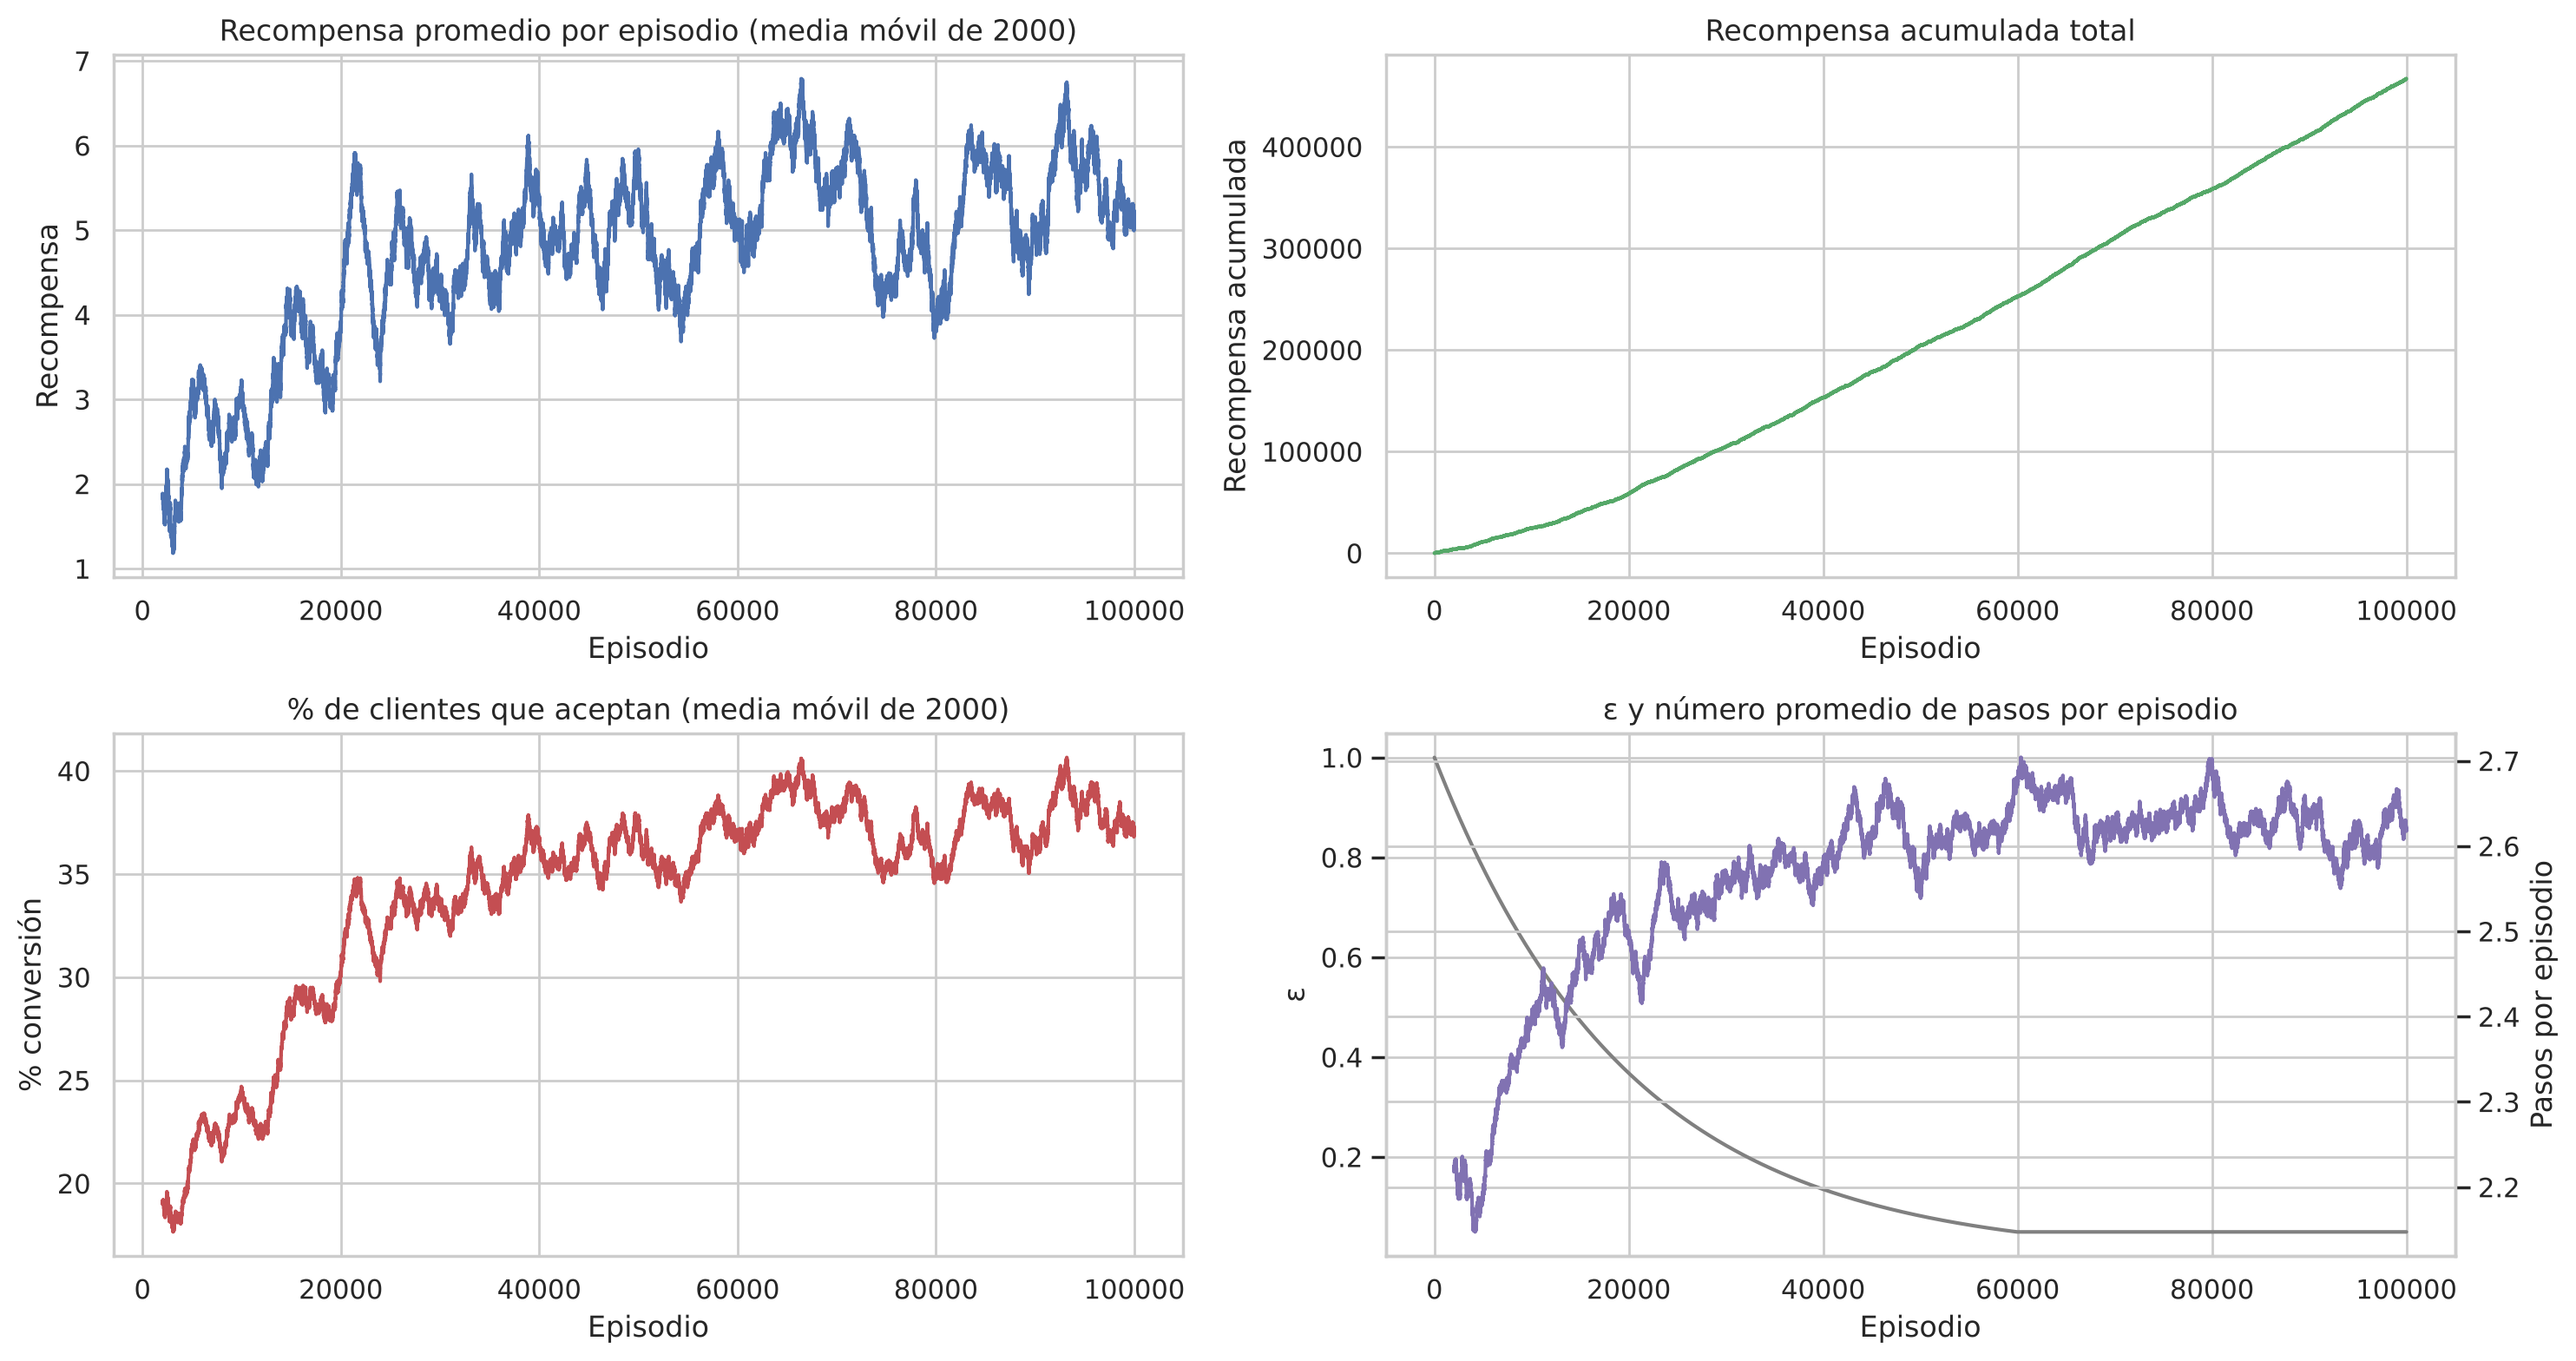

In [9]:
ventana = 2000
fig, axes = plt.subplots(2, 2, figsize=(15, 8))

axes[0, 0].plot(hist["recompensa"].rolling(ventana).mean(), color="#4C72B0")
axes[0, 0].set_title(f"Recompensa promedio por episodio (media móvil de {ventana})")
axes[0, 0].set_ylabel("Recompensa")

axes[0, 1].plot(hist["recompensa"].cumsum(), color="#55A868")
axes[0, 1].set_title("Recompensa acumulada total")
axes[0, 1].set_ylabel("Recompensa acumulada")

axes[1, 0].plot(hist["acepta"].rolling(ventana).mean() * 100, color="#C44E52")
axes[1, 0].set_title(f"% de clientes que aceptan (media móvil de {ventana})")
axes[1, 0].set_ylabel("% conversión")

axes[1, 1].plot(hist["epsilon"], color="gray", label="ε")
ax2 = axes[1, 1].twinx()
ax2.plot(hist["largo"].rolling(ventana).mean(), color="#8172B2", label="Llamadas por cliente")
axes[1, 1].set_title("ε y número promedio de pasos por episodio")
axes[1, 1].set_ylabel("ε")
ax2.set_ylabel("Pasos por episodio")

for ax in axes.flat:
    ax.set_xlabel("Episodio")
plt.tight_layout()
plt.show()

In [10]:
tramos = hist.groupby(hist.index // 20000).agg(
    recompensa_prom=("recompensa", "mean"),
    conversion_pct=("acepta", lambda s: s.mean() * 100),
    pasos_prom=("largo", "mean"),
    epsilon=("epsilon", "mean"),
)
tramos.index = [f"{i*20000+1}-{(i+1)*20000}" for i in tramos.index]
tramos.index.name = "episodios"
tramos.round(3)

,recompensa_prom,conversion_pct,pasos_prom,epsilon
episodios,,,,
1-20000,2.920,24.370,2.371,0.632
20001-40000,4.737,34.055,2.549,0.233
40001-60000,4.978,36.185,2.621,0.086
60001-80000,5.271,37.495,2.640,0.050
80001-100000,5.444,37.750,2.618,0.050


## 8. Función de valor Q y política aprendida

In [11]:
filas = []
for perfil in PERFILES:
    for k in range(MAX_CONTACTOS):
        q = Q[(perfil, k)]
        filas.append({"perfil": perfil, "llamadas_hechas": k,
                      **{f"Q_{a}": round(q[i], 2) for i, a in enumerate(ACCIONES)},
                      "mejor_accion": ACCIONES[int(np.argmax(q))],
                      "visitas": int(N[(perfil, k)].sum())})
tabla_q = pd.DataFrame(filas)
tabla_q

,perfil,llamadas_hechas,Q_fijo,Q_celular,Q_celular_promo,Q_detener,mejor_accion,visitas
0,nuevo,0,0.40,1.55,2.77,0.0,celular_promo,81883
1,nuevo,1,-0.71,-0.62,1.56,0.0,celular_promo,59604
2,nuevo,2,-1.87,-0.79,0.75,0.0,celular_promo,41616
3,nuevo,3,-1.82,-1.63,-0.97,0.0,detener,27383
4,nuevo,4,-2.24,-2.24,-0.28,0.0,detener,2400
5,fallo_previo,0,4.56,4.10,6.08,0.0,celular_promo,10167
6,fallo_previo,1,2.66,2.27,4.05,0.0,celular_promo,7055
7,fallo_previo,2,2.61,1.24,2.56,0.0,fijo,4754
8,fallo_previo,3,1.07,-0.94,0.61,0.0,fijo,3144
9,fallo_previo,4,0.29,-1.23,0.35,0.0,celular_promo,2086


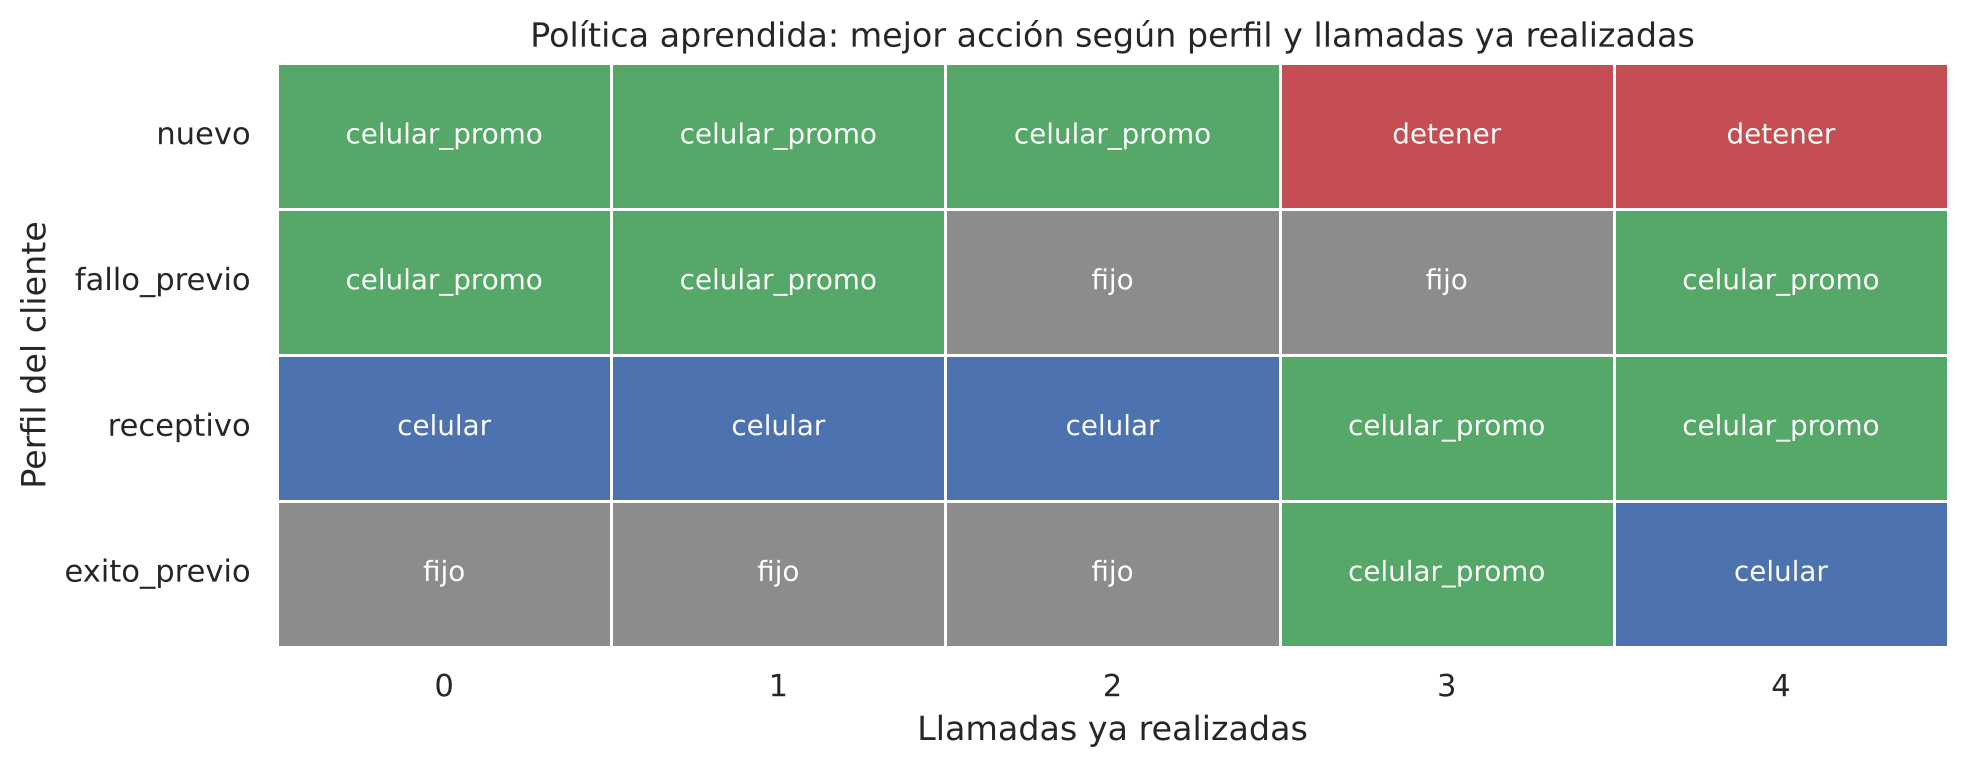

In [12]:
politica = tabla_q.pivot(index="perfil", columns="llamadas_hechas", values="mejor_accion").reindex(PERFILES)
codigo = politica.replace({a: i for i, a in enumerate(ACCIONES)}).astype(int)

colores = ["#8C8C8C", "#4C72B0", "#55A868", "#C44E52"]
fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(codigo, annot=politica.values, fmt="", cmap=sns.color_palette(colores, as_cmap=True),
            vmin=-0.5, vmax=3.5, cbar=False, linewidths=1, linecolor="white", ax=ax, annot_kws={"size": 10})
ax.set_title("Política aprendida: mejor acción según perfil y llamadas ya realizadas")
ax.set_xlabel("Llamadas ya realizadas")
ax.set_ylabel("Perfil del cliente")
plt.tight_layout()
plt.show()

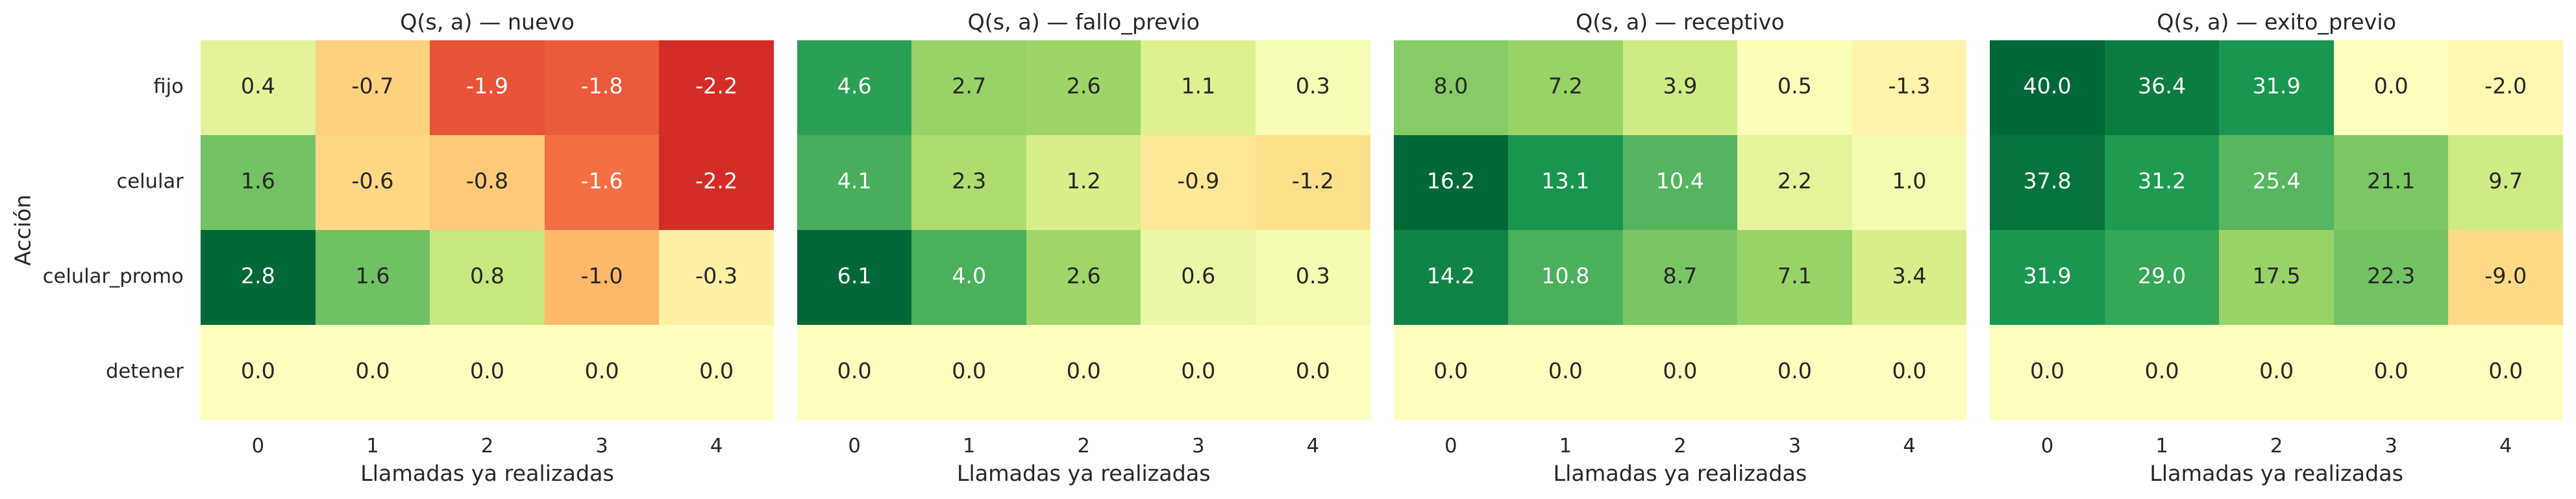

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4), sharey=True)
for ax, perfil in zip(axes, PERFILES):
    datos = tabla_q[tabla_q["perfil"] == perfil].set_index("llamadas_hechas")[[f"Q_{a}" for a in ACCIONES]]
    datos.columns = ACCIONES
    sns.heatmap(datos.T, annot=True, fmt=".1f", cmap="RdYlGn", center=0, ax=ax, cbar=False)
    ax.set_title(f"Q(s, a) — {perfil}")
    ax.set_xlabel("Llamadas ya realizadas")
axes[0].set_ylabel("Acción")
plt.tight_layout()
plt.show()

## 9. Comparación con estrategias fijas

Para saber si el agente aprendió algo útil, se compara su política (sin exploración, ε = 0) con estrategias simples que un banco podría usar sin aprendizaje por refuerzo. Cada estrategia se prueba con los mismos 20.000 clientes simulados.

In [14]:
def evaluar(politica_fn, n=20000, seed=123):
    env_eval = CampanaEnv(prob_canal, desgaste, freq_perfil, seed=seed)
    rng = np.random.default_rng(seed)
    recompensas, aceptan, llamadas = [], 0, 0
    for _ in range(n):
        estado = env_eval.reset()
        terminado, total = False, 0
        while not terminado:
            a = politica_fn(estado, rng)
            if a != 3:
                llamadas += 1
            estado, r, terminado, info = env_eval.step(a)
            total += r
        recompensas.append(total)
        aceptan += info["resultado"] == "acepta"
    return {"recompensa_promedio": np.mean(recompensas), "conversion_%": aceptan / n * 100,
            "llamadas_por_cliente": llamadas / n}

estrategias = {
    "Agente Monte Carlo": lambda s, rng: int(np.argmax(Q[s])),
    "Aleatoria": lambda s, rng: int(rng.integers(4)),
    "Siempre fijo (hasta 5 llamadas)": lambda s, rng: 0,
    "Siempre celular (hasta 5 llamadas)": lambda s, rng: 1,
    "Siempre celular + promoción": lambda s, rng: 2,
    "Una llamada al celular y detener": lambda s, rng: 1 if s[1] == 0 else 3,
}
comparacion = pd.DataFrame({k: evaluar(f) for k, f in estrategias.items()}).T.round(3)
comparacion = comparacion.sort_values("recompensa_promedio", ascending=False)
comparacion

,recompensa_promedio,conversion_%,llamadas_por_cliente
Agente Monte Carlo,5.491,38.510,2.351
Siempre celular + promoción,4.952,45.780,2.843
Una llamada al celular y detener,2.562,13.970,1.000
Siempre celular (hasta 5 llamadas),2.077,33.555,3.082
Aleatoria,1.824,18.760,1.663
Siempre fijo (hasta 5 llamadas),-0.418,18.370,3.386


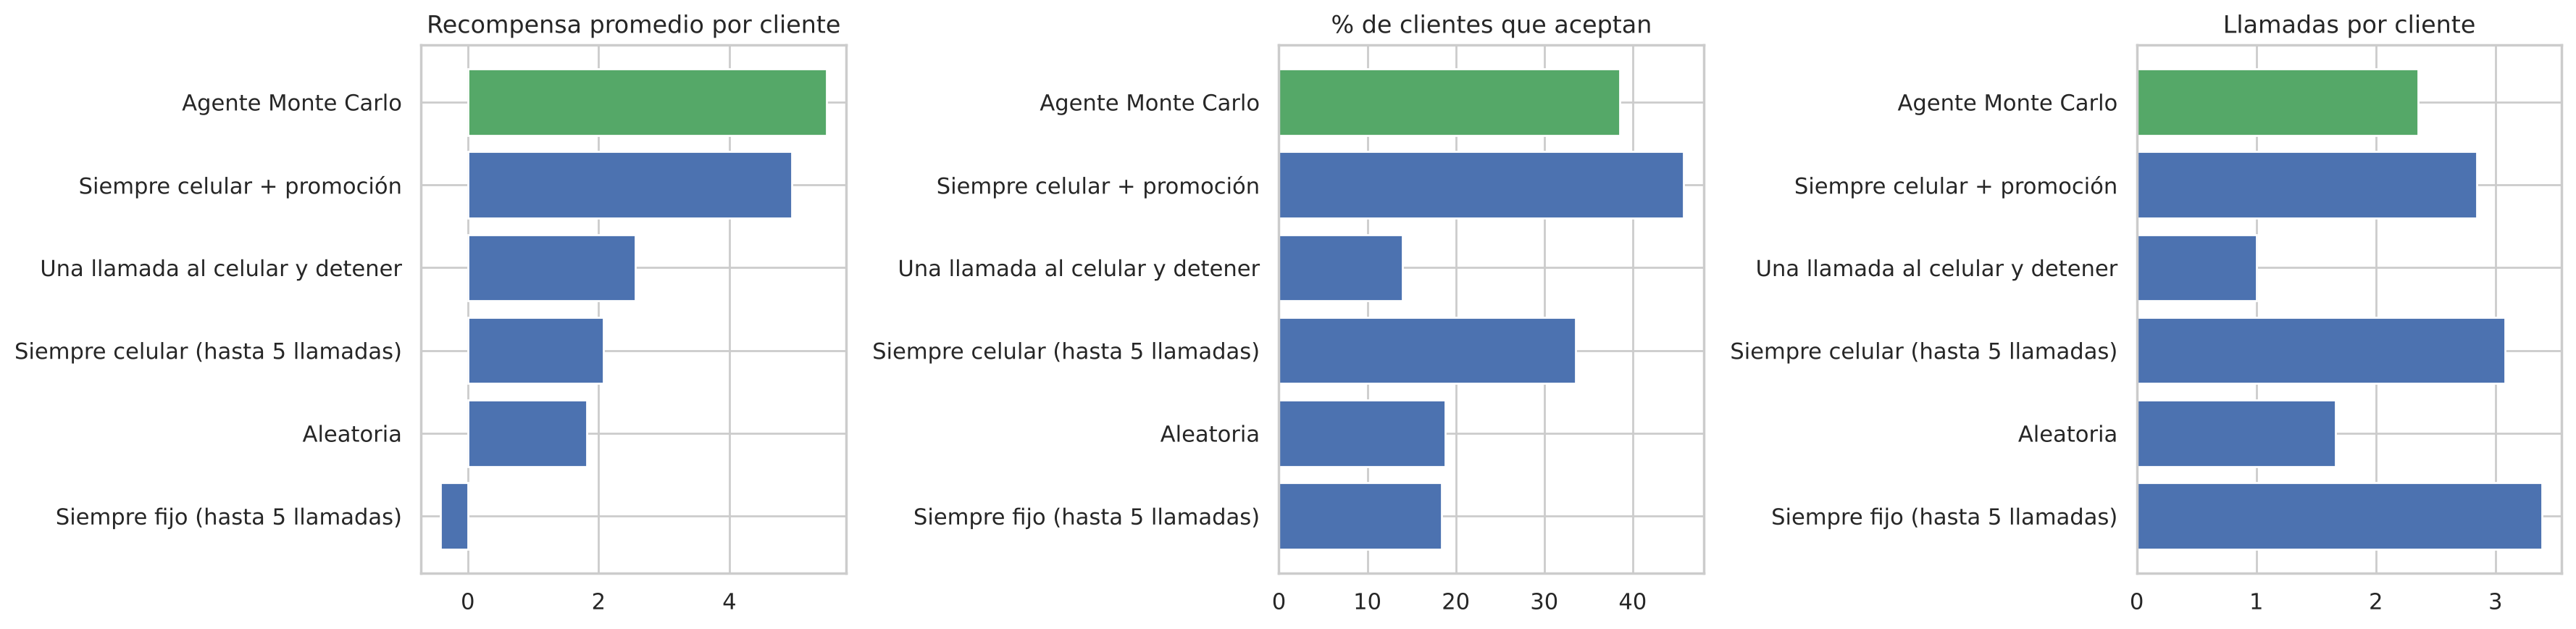

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, col, titulo in zip(axes, comparacion.columns,
                          ["Recompensa promedio por cliente", "% de clientes que aceptan", "Llamadas por cliente"]):
    colores_b = ["#55A868" if i == "Agente Monte Carlo" else "#4C72B0" for i in comparacion.index]
    ax.barh(comparacion.index[::-1], comparacion[col][::-1], color=colores_b[::-1])
    ax.set_title(titulo)
plt.tight_layout()
plt.show()

## 10. Referencia: política óptima teórica

Como el entorno fue construido en este notebook y se conocen todas sus probabilidades, se puede calcular la política óptima exacta con **programación dinámica** (ecuación de Bellman), yendo desde la última llamada hacia la primera:

$$Q^{*}(s, a) = \sum_{s', r} P(s', r \mid s, a) \left[ r + \gamma \max_{a'} Q^{*}(s', a') \right]$$

Esto **no es parte del aprendizaje** del agente (Monte Carlo nunca ve estas probabilidades, solo aprende jugando). Se usa únicamente como referencia para saber qué tan cerca llegó el agente de la mejor estrategia posible.

In [16]:
def politica_optima(gamma=0.9):
    V, pol = {}, {}
    for perfil in PERFILES:
        for k in range(MAX_CONTACTOS - 1, -1, -1):
            valores = []
            for a in range(3):
                canal = "telephone" if a == 0 else "cellular"
                p_acepta = prob_canal.loc[perfil, canal] * desgaste[k] + (EFECTO_PROMO if a == 2 else 0)
                ganancia = GANANCIA - (COSTO_PROMO if a == 2 else 0)
                p_rechazo = 0.10 + 0.05 * k
                v_siguiente = V.get((perfil, k + 1), 0) if k + 1 < MAX_CONTACTOS else 0
                valor = (p_acepta * (ganancia - COSTO[a])
                         + (1 - p_acepta) * (p_rechazo * (-COSTO[a] - PENALIZACION_RECHAZO)
                                             + (1 - p_rechazo) * (-COSTO[a] + gamma * v_siguiente)))
                valores.append(valor)
            valores.append(0.0)  # detener
            V[(perfil, k)] = max(valores)
            pol[(perfil, k)] = int(np.argmax(valores))
    return pol

pol_opt = politica_optima(gamma=PARAMS["gamma"])
tabla_opt = pd.DataFrame({k: [ACCIONES[pol_opt[(p, k)]] for p in PERFILES] for k in range(MAX_CONTACTOS)}, index=PERFILES)
tabla_opt.index.name = "perfil"
tabla_opt.columns.name = "llamadas_hechas"

coincide = (tabla_opt == politica).values.mean() * 100
ev_opt = evaluar(lambda s, rng: pol_opt[s])
ev_agente = comparacion.loc["Agente Monte Carlo"]
print(f"Coincidencia entre la política del agente y la óptima: {coincide:.0f}% de los estados")
print(f"Recompensa promedio -> agente: {ev_agente['recompensa_promedio']:.3f} | óptima: {ev_opt['recompensa_promedio']:.3f}")
print(f"El agente obtiene el {ev_agente['recompensa_promedio'] / ev_opt['recompensa_promedio'] * 100:.1f}% de la recompensa óptima")
tabla_opt

Coincidencia entre la política del agente y la óptima: 70% de los estados
Recompensa promedio -> agente: 5.491 | óptima: 5.777
El agente obtiene el 95.0% de la recompensa óptima


llamadas_hechas,0,1,2,3,4
perfil,,,,,
nuevo,celular_promo,celular_promo,celular_promo,celular_promo,detener
fallo_previo,fijo,celular_promo,celular_promo,celular_promo,celular_promo
receptivo,celular,celular,celular,celular_promo,celular_promo
exito_previo,fijo,fijo,fijo,fijo,fijo


## 11. Análisis de parámetros

Se entrena el agente con distintos valores de γ y de ε mínimo para ver cómo afectan al aprendizaje. Cada configuración se evalúa con la misma prueba de 20.000 clientes.

In [17]:
configs = [
    ("γ = 0,5", dict(gamma=0.5)),
    ("γ = 0,9 (elegido)", dict(gamma=0.9)),
    ("γ = 1,0", dict(gamma=1.0)),
    ("ε mín = 0,01", dict(eps_min=0.01)),
    ("ε mín = 0,20", dict(eps_min=0.20)),
    ("ε fijo = 0,1 (sin decaimiento)", dict(eps_inicial=0.1, eps_decay=1.0, eps_min=0.1)),
]
res_params, curvas = [], {}
for nombre, cambios in configs:
    p = {**PARAMS, **cambios}
    Q_c, _, h_c = entrenar_mc(CampanaEnv(prob_canal, desgaste, freq_perfil, seed=SEED), **p)
    ev = evaluar(lambda s, rng, Q_c=Q_c: int(np.argmax(Q_c[s])))
    res_params.append({"configuración": nombre,
                       "recompensa_entrenamiento_ultimos_10000": h_c["recompensa"].tail(10000).mean(),
                       **ev})
    curvas[nombre] = h_c["recompensa"].rolling(2000).mean()

tabla_params = pd.DataFrame(res_params).set_index("configuración").round(3)
tabla_params

,recompensa_entrenamiento_ultimos_10000,recompensa_promedio,conversion_%,llamadas_por_cliente
configuración,,,,
"γ = 0,5",5.560,5.695,41.940,2.652
"γ = 0,9 (elegido)",5.574,5.491,38.510,2.351
"γ = 1,0",5.535,5.438,38.790,2.314
"ε mín = 0,01",5.572,5.491,38.510,2.351
"ε mín = 0,20",4.967,5.528,38.415,2.354
"ε fijo = 0,1 (sin decaimiento)",5.363,5.465,38.190,2.317


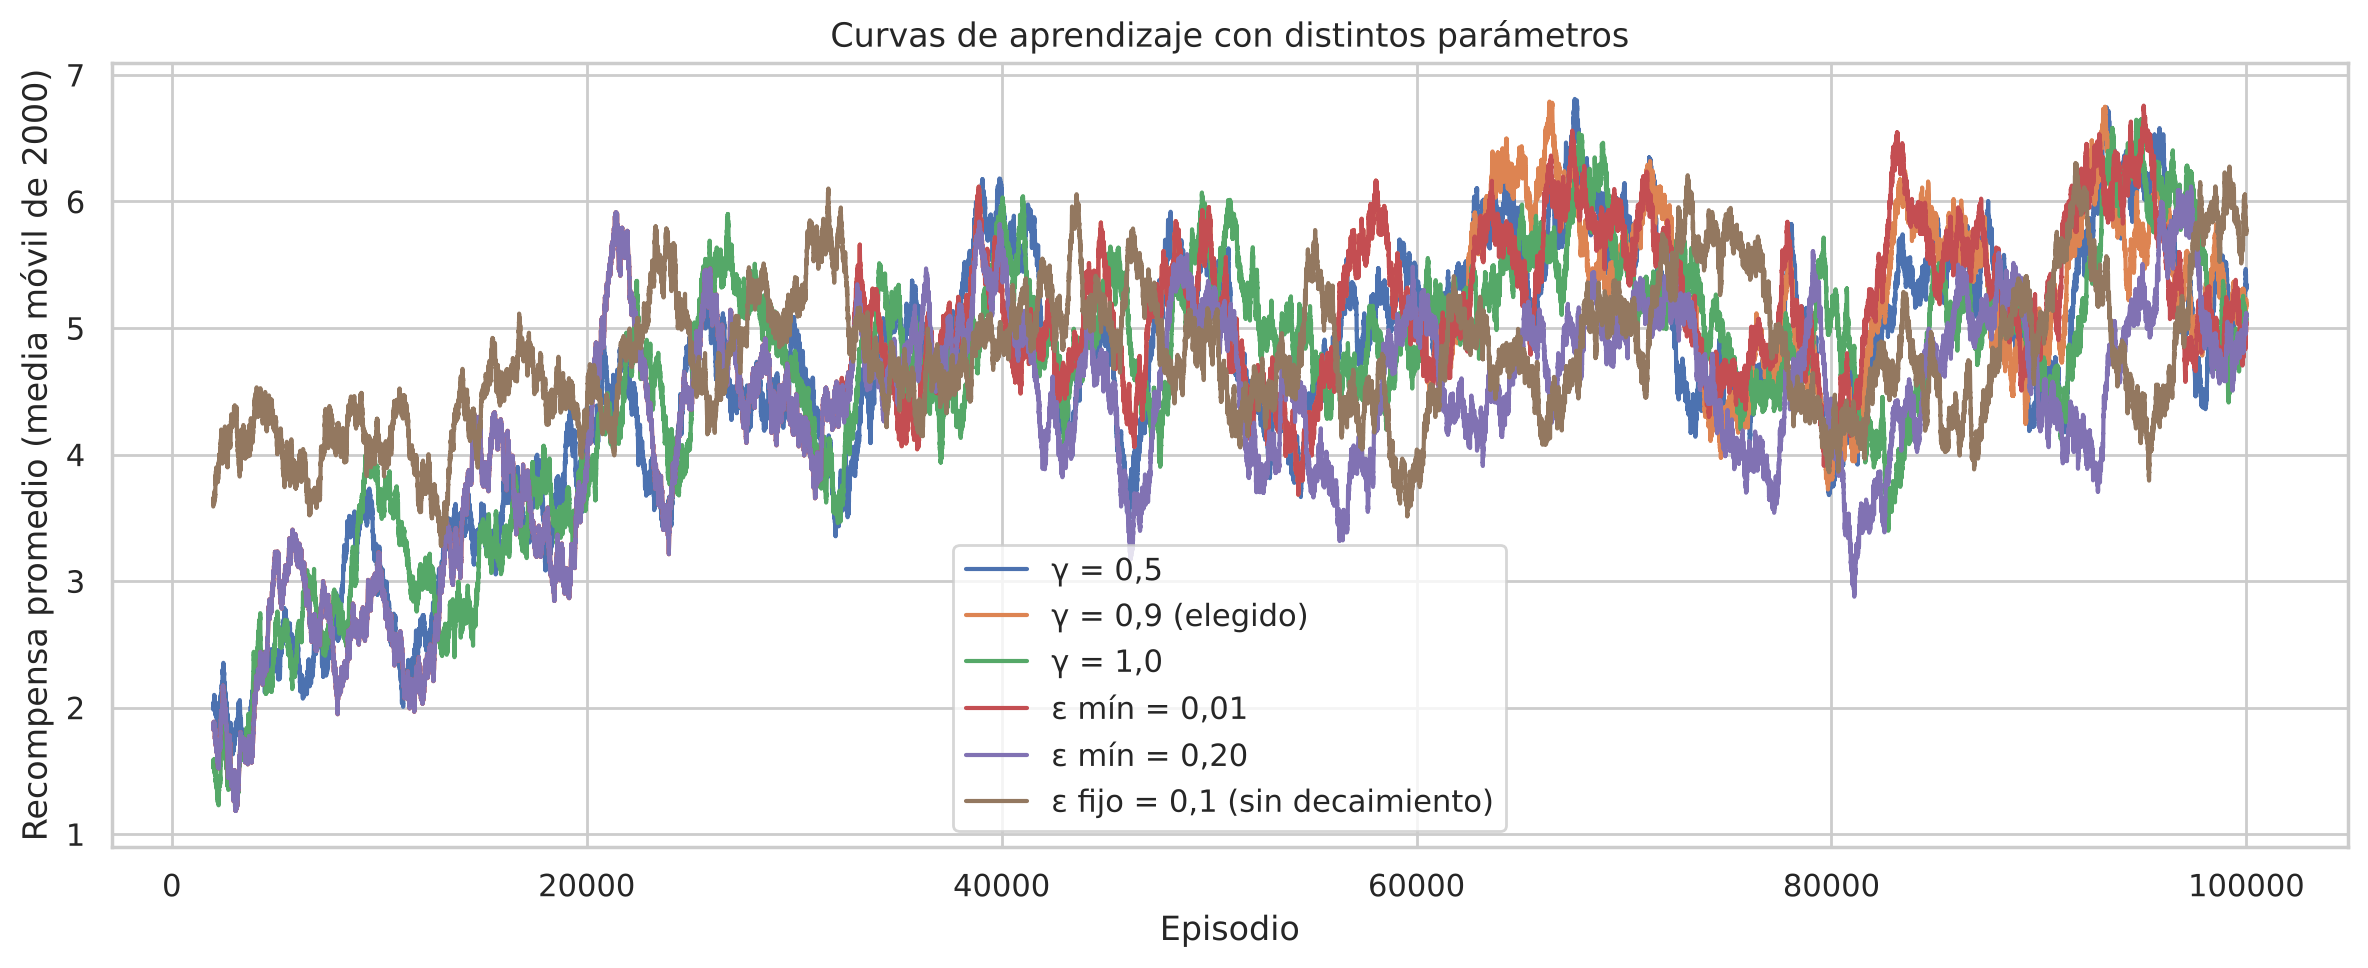

In [18]:
fig, ax = plt.subplots(figsize=(12, 5))
for nombre, curva in curvas.items():
    ax.plot(curva, label=nombre, lw=1.5)
ax.set_xlabel("Episodio")
ax.set_ylabel("Recompensa promedio (media móvil de 2000)")
ax.set_title("Curvas de aprendizaje con distintos parámetros")
ax.legend()
plt.tight_layout()
plt.show()

## 12. Guardar resultados para la comparación final

In [19]:
resultados_mc = {
    "modelo": "Monte Carlo first-visit (on-policy, ε-greedy)",
    "parametros": PARAMS,
    "estados": len(PERFILES) * MAX_CONTACTOS,
    "acciones": ACCIONES,
    "politica": {perfil: list(politica.loc[perfil].values) for perfil in PERFILES},
    "recompensa_optima": float(ev_opt["recompensa_promedio"]),
    "coincidencia_politica_optima_%": float(coincide),
    "comparacion_estrategias": comparacion.reset_index().rename(columns={"index": "estrategia"}).to_dict(orient="records"),
}
with open("../data/processed/resultados_monte_carlo.json", "w") as f:
    json.dump(resultados_mc, f, indent=2, ensure_ascii=False, default=float)
print("Guardado: resultados_monte_carlo.json")

Guardado: resultados_monte_carlo.json


## 13. Interpretación de resultados

**Sobre el aprendizaje:**

1. El agente **sí aprendió**: en los primeros 20.000 episodios (casi todo exploración) ganaba 2,92 por cliente en promedio, y en los últimos 20.000 ganó **5,44**. La conversión subió de 24,4% a 37,8%.
2. La recompensa acumulada crece cada vez más rápido (la pendiente de la curva aumenta), lo que muestra que con el tiempo el agente toma mejores decisiones.
3. Las curvas tienen bastante "ruido" porque Monte Carlo actualiza con el retorno completo de cada episodio, y ese retorno cambia mucho de un cliente a otro (algunos aceptan y dan +46, otros no y dan −4). Esta **alta varianza** es una característica conocida de Monte Carlo.

**Política aprendida (qué hacer con cada tipo de cliente):**

4. **`exito_previo` → llamar al fijo, sin promoción.** Estos clientes aceptan cerca del 65% por cualquier canal, así que conviene usar el canal más barato y no darles descuento, porque igual iban a aceptar.
5. **`receptivo` (estudiantes y jubilados) → llamar al celular sin promoción** en las primeras llamadas, porque por celular aceptan 27% contra 8,7% por fijo. La promoción solo aparece cuando ya se insistió varias veces.
6. **`nuevo` → celular con promoción hasta 3 llamadas y después detener.** Son los que menos aceptan (10,7%), así que la promoción ayuda a convencerlos, pero después de 3 intentos ya no conviene seguir porque cada llamada cuesta y aumenta el riesgo de molestar al cliente.
7. **`fallo_previo` → principalmente celular con promoción.**
8. En resumen, el agente aprendió una regla lógica: **dar la promoción solo a los clientes que la necesitan para aceptar** y no insistir de más con los clientes poco receptivos.

**Comparación con otras estrategias:**

9. El agente obtiene la **mayor recompensa promedio (5,49 por cliente)**, por encima de todas las estrategias fijas: siempre promoción (4,95), una sola llamada (2,56), siempre celular (2,08), aleatoria (1,82) y siempre fijo (−0,42, pierde dinero).
10. "Siempre celular + promoción" consigue más conversiones (45,8% contra 38,5%), pero **gana menos**, porque le da descuento a todos (incluso a los que igual iban a aceptar) y hace más llamadas (2,84 contra 2,35 por cliente). Esto muestra que **maximizar conversiones no es lo mismo que maximizar ganancia**.
11. Comparado con la política óptima teórica (calculada con programación dinámica conociendo todo el modelo), el agente obtiene el **95% de la recompensa máxima posible** y coincide en el 70% de los estados, sin haber conocido nunca las probabilidades del entorno.
12. Los estados donde el agente no coincide con la óptima son los que **menos visitó** (por ejemplo `exito_previo` con 3 o 4 llamadas tiene menos de 110 visitas), porque los clientes con éxito previo son solo el 3,3% y casi siempre aceptan en la primera llamada. Con tan pocas visitas, el promedio de $Q$ todavía no es confiable.

**Análisis de parámetros:**

13. **γ (factor de descuento):** con γ = 0,5 la evaluación salió un poco mejor (5,70) que con 0,9 (5,49) o 1,0 (5,44). Las diferencias son pequeñas porque los episodios son cortos (máximo 5 llamadas), así que el descuento casi no cambia el valor de las recompensas futuras.
14. **ε mínimo:** con ε mín = 0,20 la recompensa durante el entrenamiento fue más baja (4,97) porque el agente sigue explorando mucho, aunque la política final es parecida. Con 0,01 y 0,05 los resultados son iguales.
15. **ε fijo en 0,1 (sin decaimiento):** funciona un poco peor (5,47), porque al inicio no explora lo suficiente y algunas acciones casi no se prueban.

**Limitaciones:**

16. Los valores de recompensa (ganancia de 50, costos de llamada, costo de la promoción) y el efecto de la promoción son **supuestos**, porque el dataset no tiene esa información. Si cambian, la política óptima también puede cambiar.
17. Las tasas de conversión del dataset son por cliente y no por llamada, así que la simulación es una aproximación.
18. El estado es simple (perfil + número de llamadas). Un entorno más realista podría incluir el mes, el contexto económico o la edad.
19. Monte Carlo necesita muchos episodios y tiene alta varianza, sobre todo en estados poco frecuentes. Métodos como SARSA o Q-Learning actualizan en cada paso y podrían aprender más rápido.
